# Bayesian full-waveform inversion of ambient-noise correlograms for $V_s(z)$

The dispersion-curve workflow (`site_characterization.ipynb`) compresses the noise correlations into one picked curve and fits a 3-parameter model. Here we fit the **correlograms themselves** with the same SH wave equation that generated them.

**The PDE is the forward operator of a Bayesian inverse problem.** With $m = \ln\beta$ per layer,

$$p(m \mid D) \;\propto\; \underbrace{\exp\!\Big(-\tfrac12 \sum_{f,j} \frac{|s(f)\,C_j(f;m) - D_j(f)|^2}{\sigma^2_{fj}}\Big)}_{\text{likelihood: PDE solve } m \mapsto C(m)} \;\underbrace{\exp\!\Big(-\tfrac{1}{2}\frac{\|m - m_0\|^2}{\sigma_m^2}\Big)}_{\text{prior}}$$

* $C_j(f;m)$: predicted correlation between channel 0 and channel $j$, built from **one** impulse solve of $\rho u_{tt} = \nabla\!\cdot(\mu\nabla u)$ (translation invariance: $C_j = \sum_s w_s\,\overline{G(|x_s-x_0|)}\,G(|x_s - x_j|)$).
* $s(f)$: the unknown noise-source spectrum, eliminated in closed form at every frequency (variable projection).
* $\sigma^2_{fj}$: data variance from the scatter of 10 sub-stacks, **plus** a modelling-error variance (below).

FWI = the **MAP** estimate (minimise $-\ln p$ with adjoint-state gradients and L-BFGS). Uncertainty = **Laplace approximation**: a Gaussian with covariance $(J^\top C_d^{-1}J + C_m^{-1})^{-1}$ at the MAP point.

Model: 7 layers with tops at 0, 3, 6, 10, 15, 20, 30 m (the last is the half-space), densities known. True site: 250 m/s over 15 m on 800 m/s ($V_{s30} = 381$ m/s, NEHRP C). The data come from the 1 m grid of the site notebook; the inversion uses a 2 m grid, so there is **no inverse crime**.

In [1]:
import time, os, numpy as np, matplotlib.pyplot as plt
import love_waves as L, fwi
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
RUN_FULL = False        # True: rerun the inversions (~45 min); False: load results/fwi_results.npz
lay = fwi.Layers()
rx = L.channels(48, 4.0, -90.0)                  # 48 channels, 4 m apart (188 m line)
src = fwi.line_noise_sources(rx)                 # noise sources 30-120 m beyond both ends
true = np.log([250.0] * 4 + [800.0] * 3)
m0 = np.log([300, 330, 360, 400, 480, 560, 650.0])   # prior mean: a smooth, generic gradient
inv = fwi.NoiseFWI(lay, rx, src, m0=m0, prior_std=0.5)
print(f"inversion grid: dx = {inv.prop.g.dx} m, {inv.prop.g.nz} x {inv.prop.g.nx} nodes, "
      f"{inv.prop.nt} time steps, records every {inv.prop.t_rec[1]*1e3:.1f} ms to {inv.prop.t_rec[-1]:.1f} s")
print("true Vs30 =", round(fwi.vs30_layers(lay, np.exp(true)), 1), " prior-mean Vs30 =", round(fwi.vs30_layers(lay, np.exp(m0)), 1))

inversion grid: dx = 2.0 m, 151 x 411 nodes, 3601 time steps, records every 2.0 ms to 3.6 s
true Vs30 = 381.0  prior-mean Vs30 = 422.7


## 1. Observed data
400 windows of simulated random noise on the **1 m** grid (true model), stacked in 10 sub-stacks. The mean is $D$; the sub-stack scatter gives $\sigma^2$.

observed data built in 33 s; 1802 frequencies x 48 channels


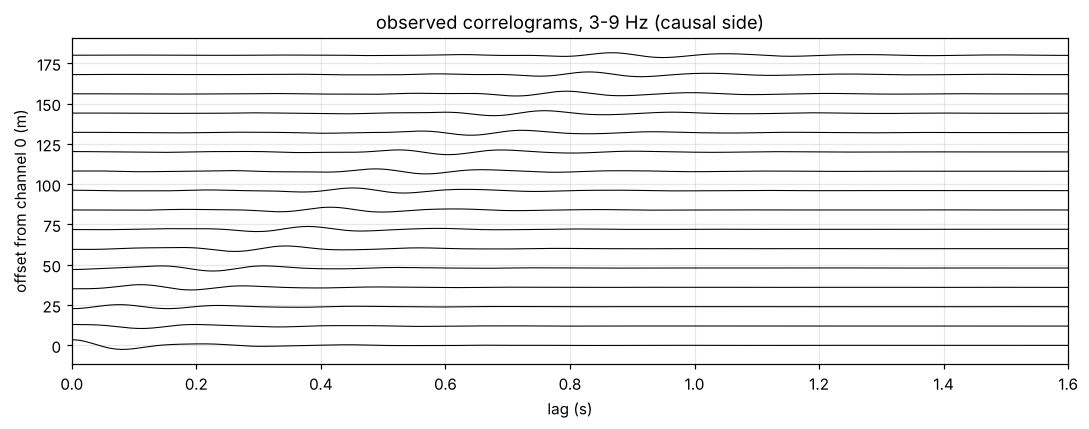

In [2]:
t0 = time.time()
line_true = L.LoveLine(L.Site())                 # 1 m grid, true site
D, var = inv.observe_from(line_true, n_windows=400, n_sub=10, seed=0)
inv.set_data(D, var, (3, 9))
print(f"observed data built in {time.time() - t0:.0f} s; {D.shape[0]} frequencies x {D.shape[1]} channels")

def lagtrace(X, band=(3, 9)):
    inv.set_band(band)
    return np.fft.irfft(inv.win[:, None] * X, inv.nfft, axis=0)[:len(inv.prop.t_rec)]
tr = lagtrace(D); off = rx - rx[0]
fig, ax = plt.subplots(figsize=(10, 4))
for j in range(0, 48, 3):
    ax.plot(inv.prop.t_rec, off[j] + 3.5 * tr[:, j] / np.abs(tr).max(), "k", lw=0.7)
ax.set(xlim=(0, 1.6), xlabel="lag (s)", ylabel="offset from channel 0 (m)", title="observed correlograms, 3-9 Hz (causal side)")
plt.tight_layout()

## 2. Verification: the adjoint-state gradient
One forward solve stores the wavefield; one adjoint solve (the transposed discrete operator, run backwards, driven by the data residual) gives $\partial\chi/\partial\mu$ at every grid face; the chain rule maps that to the layers. We check it against central finite differences of the objective for every layer.

In [3]:
inv.set_data(D, var, (3, 7))
mt = np.log([280, 300, 320, 330, 520, 700, 760.0])      # an arbitrary test model
t0 = time.time(); J0, g = inv.objective(mt); t_grad = time.time() - t0
h = 1e-4
fd = np.array([(inv.objective(mt + h * e, grad=False) - inv.objective(mt - h * e, grad=False)) / (2 * h) for e in np.eye(7)])
print(f"one objective + adjoint gradient: {t_grad:.1f} s")
print(" layer   adjoint        finite diff    ratio")
for k in range(7):
    print(f"  {k}   {g[k]:13.5e}  {fd[k]:13.5e}  {g[k] / fd[k]:.8f}")
print("max relative difference:", np.max(np.abs(g - fd) / np.abs(fd)))
inv.history.clear()

one objective + adjoint gradient: 10.1 s
 layer   adjoint        finite diff    ratio
  0     1.48250e+04    1.48250e+04  0.99999995
  1     1.87825e+04    1.87825e+04  0.99999996
  2     3.26274e+04    3.26274e+04  0.99999995
  3     4.96786e+04    4.96786e+04  0.99999997
  4     3.08004e+04    3.08004e+04  0.99999999
  5     4.37802e+04    4.37802e+04  1.00000000
  6     7.76405e+04    7.76404e+04  1.00000014
max relative difference: 1.4258931098831195e-07


## 3. Modelling error (Bayesian approximation-error approach)
The 2 m inversion grid is cheaper but has more numerical dispersion than the 1 m data grid, so even the **true** model cannot fit the data to the noise level at high frequency. Ignoring that makes the posterior over-confident and biased (we saw the true model fit worse than the MAP model, and deep layers miss the truth by many "standard deviations").

Fix: estimate the error $e = D_{1\,\text{m}}(m^\*) - s\,C_{2\,\text{m}}(m^\*)$ at a model the inversion is allowed to know, and add $|e|^2$ (smoothed over channels) to $\sigma^2$. We use the stage-1 MAP model $m^\*$ (iterative approximation error, not the truth).

**Stage 1**: multiscale MAP (3-5, 3-7, 3-10 Hz) with noise variance only. **Stage 2**: re-estimate the modelling error at the stage-1 MAP, refit 3-9 Hz, then compute the Laplace posterior.

In [4]:
RES = "results/fwi_results.npz"
if RUN_FULL or not os.path.exists(RES):
    inv.set_data(D, var, (3, 5))
    m1 = inv.fit(m0, bands=((3, 5), (3, 7), (3, 10)), bounds=(np.log(120), np.log(1150)), maxiter=50)
    hist1 = inv.history[:]; inv.history.clear()
    ref = L.LoveLine(fwi.LayeredSite(lay, np.exp(m1)))       # stage-1 model on the 1 m grid
    merr = inv.model_error_var(ref, m1)
    inv.set_data(D, var + merr, (3, 9))
    m2 = inv.fit(m1, bands=((3, 9),), bounds=(np.log(120), np.log(1150)), maxiter=40)
    hist2 = inv.history[:]
    Cov, J = inv.laplace(m2)
    pack = lambda h: (np.array([x[1] + x[2] for x in h]), np.array([x[3] for x in h]), np.array([x[0][1] for x in h]))
    o1, b1, f1 = pack(hist1); o2, b2, f2 = pack(hist2)
    os.makedirs("results", exist_ok=True)
    np.savez(RES, m1=m1, m2=m2, merr=merr, Cov=Cov, o1=o1, b1=b1, f1=f1, o2=o2, b2=b2, f2=f2)
r = np.load(RES)
m1, m2, merr, Cov = r["m1"], r["m2"], r["merr"], r["Cov"]
print("stage-1 MAP beta:", np.round(np.exp(m1)))
print("stage-2 MAP beta:", np.round(np.exp(m2)))
print("true beta:       ", np.round(np.exp(true)))

stage-1 MAP beta: [249. 262. 242. 257. 605. 950. 764.]
stage-2 MAP beta: [249. 250. 253. 260. 541. 960. 767.]
true beta:        [250. 250. 250. 250. 800. 800. 800.]


chi^2 per complex datum, 3-9 Hz (should be ~1 if model and variance are right)
                      noise var only    noise + model error


  stage-1 MAP           1.02              0.69


  stage-2 MAP           1.01              0.68


  TRUE model            1.84              0.91
median modelling-error / noise variance in band: 0.3


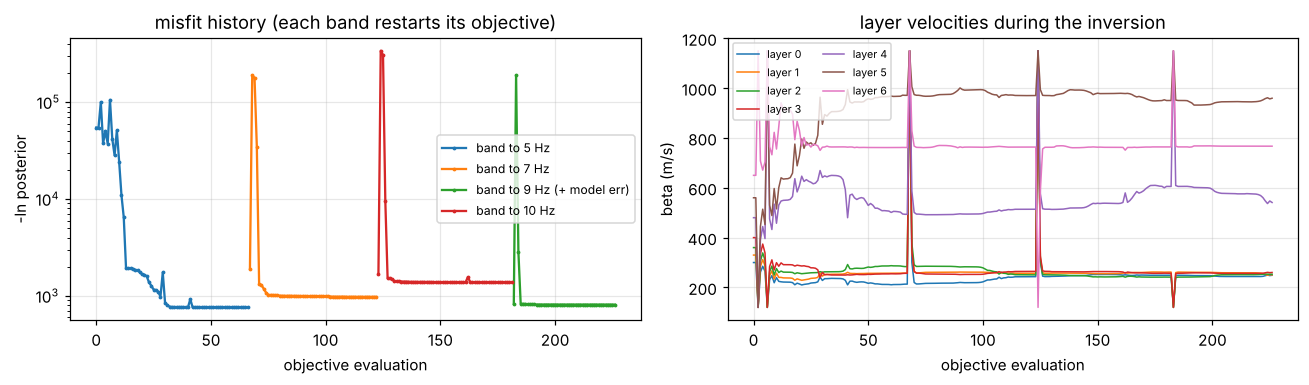

In [5]:
def chi2N(m, v, band):
    inv.set_data(D, v, band)
    _, R, chi = inv.misfit_parts(inv.spectra(inv.prop.forward(inv.mu(m)))[1])
    return 2 * chi / (np.sum(inv.win > 0.5) * D.shape[1])
print("chi^2 per complex datum, 3-9 Hz (should be ~1 if model and variance are right)")
print(f"                      noise var only    noise + model error")
for name, mm in [("stage-1 MAP", m1), ("stage-2 MAP", m2), ("TRUE model ", true)]:
    print(f"  {name}          {chi2N(mm, var, (3, 9)):5.2f}             {chi2N(mm, var + merr, (3, 9)):5.2f}")
inv.set_band((3, 9))
print("median modelling-error / noise variance in band:", round(float(np.median((merr / var)[inv.win > 0.5])), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
o = np.r_[r["o1"], r["o2"]]; fb = np.r_[r["f1"], r["f2"]]
for fm in np.unique(fb):
    k = np.where(fb == fm)[0]; ax[0].semilogy(k, o[k], ".-", ms=3, label=f"band to {fm:g} Hz" + (" (+ model err)" if k[0] >= len(r["o1"]) else ""))
ax[0].set(xlabel="objective evaluation", ylabel="-ln posterior", title="misfit history (each band restarts its objective)"); ax[0].legend(fontsize=8)
bb = np.r_[r["b1"], r["b2"]]
for k in range(7):
    ax[1].plot(bb[:, k], lw=1, label=f"layer {k}")
ax[1].set(xlabel="objective evaluation", ylabel="beta (m/s)", title="layer velocities during the inversion"); ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout()

## 4. Data fit
Observed correlograms (black) vs the stage-2 MAP prediction $s\,C(m)$ (red), 3-9 Hz.

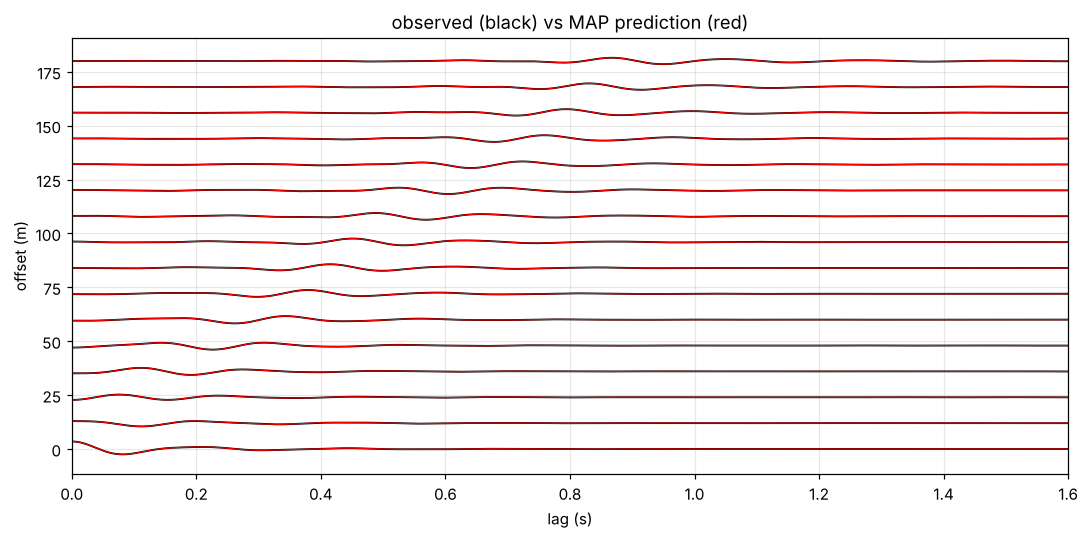

In [6]:
inv.set_data(D, var + merr, (3, 9))
s, R, _ = inv.misfit_parts(inv.spectra(inv.prop.forward(inv.mu(m2)))[1])
to, tp = lagtrace(D), lagtrace(s[:, None] * inv.spectra(inv.prop.forward(inv.mu(m2)))[1])
sc = 3.5 / np.abs(to).max()
fig, ax = plt.subplots(figsize=(10, 5))
for j in range(0, 48, 3):
    ax.plot(inv.prop.t_rec, off[j] + sc * to[:, j], "k", lw=1.2)
    ax.plot(inv.prop.t_rec, off[j] + sc * tp[:, j], "r", lw=0.7)
ax.set(xlim=(0, 1.6), xlabel="lag (s)", ylabel="offset (m)", title="observed (black) vs MAP prediction (red)")
plt.tight_layout()

## 5. Posterior
Gaussian (Laplace) posterior on $\ln\beta$; we draw samples to propagate it to the profile and to $V_{s30}$.

In [7]:
sd = np.sqrt(np.diag(Cov))
print(" layer  depth (m)     MAP     true    1-sigma range       |MAP-true|/sigma")
tops = list(lay.tops) + [np.inf]
for k in range(7):
    lo, hi = np.exp(m2[k] - sd[k]), np.exp(m2[k] + sd[k])
    print(f"  {k}    {tops[k]:4.0f}-{tops[k+1]:<4.0f}   {np.exp(m2[k]):6.0f}  {np.exp(true[k]):6.0f}    {lo:5.0f} - {hi:5.0f}         {abs(m2[k] - true[k]) / sd[k]:.1f}")
rng = np.random.default_rng(0)
smp = np.exp(rng.multivariate_normal(m2, Cov, 4000))
v30 = np.array([fwi.vs30_layers(lay, b) for b in smp])
v30_true = fwi.vs30_layers(lay, np.exp(true))
print(f"\nVs30 posterior: {v30.mean():.1f} +- {v30.std():.1f} m/s  (true {v30_true:.1f});  class {L.site_class(v30.mean())}")
print("P(NEHRP class C | data) =", np.mean((v30 > 360) & (v30 <= 760)))

 layer  depth (m)     MAP     true    1-sigma range       |MAP-true|/sigma
  0       0-3         249     250      215 -   288         0.0
  1       3-6         250     250      184 -   340         0.0
  2       6-10        253     250      204 -   314         0.1
  3      10-15        260     250      231 -   293         0.3
  4      15-20        541     800      438 -   668         1.8
  5      20-30        960     800      922 -   998         4.6
  6      30-inf       767     800      765 -   770         12.9

Vs30 posterior: 374.6 +- 8.2 m/s  (true 381.0);  class C (very dense soil)
P(NEHRP class C | data) = 0.94


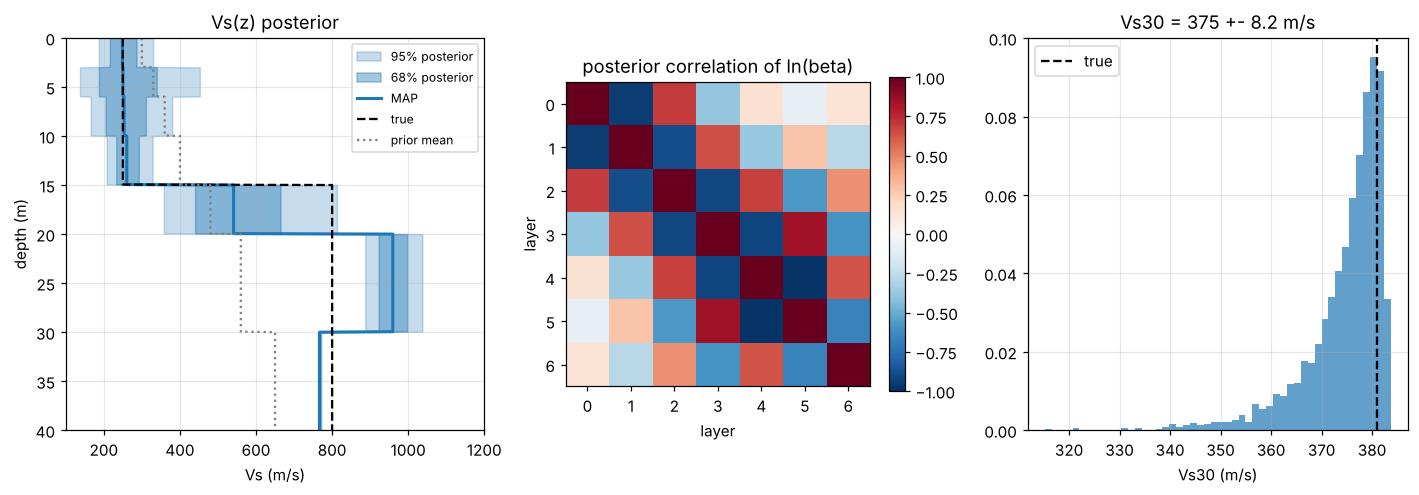

In [8]:
z = np.linspace(0, 40, 801)
prof = np.array([lay.beta_profile(b, z) for b in smp])
fig, ax = plt.subplots(1, 3, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1.1, 1, 1]))
a = ax[0]
a.fill_betweenx(z, *np.percentile(prof, [2.5, 97.5], 0), color="C0", alpha=0.25, label="95% posterior")
a.fill_betweenx(z, *np.percentile(prof, [16, 84], 0), color="C0", alpha=0.4, label="68% posterior")
a.plot(lay.beta_profile(np.exp(m2), z), z, "C0", lw=2, label="MAP")
a.plot(lay.beta_profile(np.exp(true), z), z, "k--", lw=1.5, label="true")
a.plot(lay.beta_profile(np.exp(m0), z), z, ":", color="grey", label="prior mean")
a.set(xlabel="Vs (m/s)", ylabel="depth (m)", ylim=(40, 0), xlim=(100, 1200), title="Vs(z) posterior"); a.legend(fontsize=8)
cor = Cov / np.outer(sd, sd)
im = ax[1].imshow(cor, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set(xticks=range(7), yticks=range(7), title="posterior correlation of ln(beta)", xlabel="layer", ylabel="layer"); ax[1].grid(False)
plt.colorbar(im, ax=ax[1], shrink=0.8)
ax[2].hist(v30, 50, density=True, color="C0", alpha=0.7)
ax[2].axvline(v30_true, color="k", ls="--", label="true")
ax[2].set(xlabel="Vs30 (m/s)", title=f"Vs30 = {v30.mean():.0f} +- {v30.std():.1f} m/s"); ax[2].legend()
plt.tight_layout()

## 6. What this shows, and its limits
* **The PDE is the likelihood's forward map**; FWI is the MAP estimate and the Gauss-Newton Hessian gives a Laplace posterior. The adjoint gradient costs about two wave solves regardless of the number of layers.
* **Vs30 is very well determined** (MAP 381 m/s; the sampled posterior is skewed low because the strongly anti-correlated layers keep the 30 m travel time fixed to first order, and any second-order spread can only add travel time); it is a travel-time average, which is what surface waves constrain best. Individual thin layers trade off strongly with their neighbours (negative correlations), so their posteriors are wide even when Vs30 is tight.
* **Model error matters as much as noise.** With noise variance alone, the true model fit the data worse than the MAP model ($\chi^2/N$ 1.8 vs 1.0) and the posterior excluded the truth in most layers. Adding the approximation-error variance brings the true model to $\chi^2/N \approx 0.9$ and makes the top 15 m and Vs30 consistent with the truth.
* **The deep layers (below 15 m) are still over-confident.** The MAP spreads the 250 to 800 m/s jump over layers 4-5 (low then high) and its half-space is a few percent slow, yet the Laplace sigmas there are only a few percent. The reason: the modelling error is *systematic* (strongly correlated across channels and frequencies), but we added it as independent, diagonal variance, and the sub-stack variances ignore correlations between neighbouring frequencies too. Both shrink the error bars. A full error covariance (or inflating sigma by the effective number of independent data) is the next fix.
* Other caveats: the Laplace posterior is local and Gaussian; the source distribution is assumed known up to $s(f)$; the earth is 1D; densities are fixed. An MCMC on the cheaper dispersion-curve forward model is the natural check of the Gaussian approximation.